# BAN4550 Project 2 — Quarterly SUE and Daily CAR

**Research question:** Do better-than-expected earnings come with higher stock returns?

Adapted from the supplied Assignment 8 WRDS notebook and organized around the Project 2 report requirements.

- Industry: SIC 36
- Client: NVIDIA (`NVDA`)
- Announcement window: January 2021–December 2024
- SUE = (quarter EPS − EPS four quarters earlier) / absolute price at the end of the previous quarter
- Daily abnormal return = stock return − CRSP value-weighted market return
- CAR = abnormal returns on trading days −1, 0, and +1

Run all cells from top to bottom in an environment with WRDS access. Missing values are not replaced with zero. If duplicate company-quarter keys remain, the notebook stops so they can be investigated.

## Step 0. Setup

In [1]:
# Step 0. Import libraries, connect to WRDS, and set project parameters (adapted from Assignment 8).
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import wrds
from IPython.display import display
import matplotlib.pyplot as plt
#import seaborn as sns                      # a library on top of matplotlib: nicer defaults with less code
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
import wrds
LABELS = ["Low", "Middle", "High"]
conn = wrds.Connection()

SIC = "36"  #36 49
CLIENT_TICKER = "Electronic Equipment"#NVDA

ANN_START = pd.Timestamp("2021-01-01")
ANN_END = pd.Timestamp("2024-12-31")
PULL_START = "2019-01-01"       # history for EPS four quarters earlier and prior-quarter price
RET_START = "2020-12-15"        # buffer for daily event windows
RET_END = "2025-01-10"
MIN_PRICE = 5
MAX_ABS_SUE = 1

print("SIC:", SIC, "| Client:", CLIENT_TICKER)

print("Announcement window:", ANN_START.date(), "to", ANN_END.date())

Loading library list...
Done
SIC: 36 | Client: Electronic Equipment
Announcement window: 2021-01-01 to 2024-12-31


## Step 1. Read the supplied CCM link file

In [2]:
# Step 1. Read and prepare CCM identifiers and link dates (adapted from Assignment 8).
link_all = pd.read_csv("ccm_link.csv", dtype=str)
required = {"gvkey", "permno", "linkdt", "linkenddt", "sic2", "ticker"}
missing = required - set(link_all.columns)
if missing:
    raise ValueError(f"ccm_link.csv is missing columns: {sorted(missing)}")

link_all["gvkey"] = link_all["gvkey"].str.strip().str.zfill(6)
link_all["permno"] = pd.to_numeric(link_all["permno"], errors="coerce")
link_all["linkdt"] = pd.to_datetime(link_all["linkdt"], errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], errors="coerce")
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

link = link_all.loc[link_all["sic2"].astype(str).str.zfill(2).eq(SIC)].copy()
link = link.dropna(subset=["gvkey", "permno", "linkdt", "ticker"])
link["permno"] = link["permno"].astype(int)
if link.empty:
    raise ValueError(f"No links found for SIC {SIC}.")

print("Industry link rows:", len(link), "| companies:", link["gvkey"].nunique())


Industry link rows: 240 | companies: 214


## Step 2. Pull quarterly Compustat data

In [3]:
# Step 2. Pull quarterly EPS, price, fiscal-quarter identifiers, and announcement dates.
gvkeys = sorted(link["gvkey"].dropna().unique().tolist())
gv_sql = ",".join("'" + x.replace("'", "''") + "'" for x in gvkeys)

sql_fq = (
    "select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq "
    "from comp.fundq "
    f"where gvkey in ({gv_sql}) "
    f"and datadate between '{PULL_START}' and '{ANN_END.date()}' "
    "and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'"
)
fq = conn.raw_sql(sql_fq, date_cols=["datadate", "rdq"])
for col in ["fyearq", "fqtr", "epspxq", "prccq"]:
    fq[col] = pd.to_numeric(fq[col], errors="coerce")
fq["gvkey"] = fq["gvkey"].astype(str).str.zfill(6)
fq = fq.sort_values(["gvkey", "datadate"]).reset_index(drop=True)

print("Quarterly Compustat rows:", len(fq), "| companies:", fq["gvkey"].nunique())
display(fq.head())

Quarterly Compustat rows: 4533 | companies: 209


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,001117,2019-03-31,2019,1,2019-05-08,-0.1,4.27
1,001117,2019-06-30,2019,2,2019-08-06,-0.02,4.3
2,001117,2019-09-30,2019,3,2019-11-06,0.02,3.36
3,001117,2019-12-31,2019,4,2020-03-04,-0.1,3.1
4,001117,2020-03-31,2020,1,2020-05-13,-0.09,1.66


## Step 3. Merge CCM links and construct SUE

In [4]:
# Step 3a. Merge 1: attach PERMNO and retain CCM links valid on the quarter-end date.
# Validity rule follows the report plan: linkdt <= datadate <= linkenddt.
rows_before_merge1 = len(fq)
panel = fq.merge(
    link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]],
    on="gvkey", how="inner", validate="many_to_many"
)
panel = panel.loc[panel["datadate"].between(panel["linkdt"], panel["linkenddt"])].copy()
panel["permno"] = panel["permno"].astype(int)
rows_after_merge1 = len(panel)
print("Merge 1 — Compustat + valid CCM link")
print("Rows before:", rows_before_merge1, "| after:", rows_after_merge1,
      "| removed:", rows_before_merge1 - rows_after_merge1)

Merge 1 — Compustat + valid CCM link
Rows before: 4533 | after: 4345 | removed: 188


In [5]:
# Step 3b. Clean company-quarter records and check duplicates

panel = panel.sort_values(["gvkey", "datadate"]).copy()

# Remove repeated records only when the company, date, and
# variables used in the analysis are identical.
panel = panel.drop_duplicates(
    subset=["gvkey", "datadate", "permno",
            "rdq", "epspxq", "prccq"],
    keep="last"
)

# Check that each company has one observation per reporting date
print("Duplicate company-date keys:",
      panel.duplicated(["gvkey", "datadate"]).sum())

# Stop if any conflicting records remain
assert panel.duplicated(["gvkey", "datadate"]).sum() == 0


# Step 3c. Add EPS four quarters ago and price one quarter ago

panel = panel.sort_values(["gvkey", "datadate"]).copy()


# Step 3c. Add EPS four quarters ago and price one quarter ago
# using fiscal year and fiscal quarter numbers.

panel = panel.copy()

# Create a numeric quarter identifier
panel["quarter_num"] = (
    panel["fyearq"] * 4 + panel["fqtr"]
)

# Create a lookup table for historical quarterly data
quarter_lookup = panel[
    ["gvkey", "quarter_num", "epspxq", "prccq"]
].copy()

# Match EPS from exactly four fiscal quarters earlier
eps_lookup = quarter_lookup.copy()
eps_lookup["quarter_num"] = eps_lookup["quarter_num"] + 4

panel = panel.merge(
    eps_lookup[["gvkey", "quarter_num", "epspxq"]],
    on=["gvkey", "quarter_num"],
    how="left",
    suffixes=("", "_lag4")
)

panel = panel.rename(
    columns={"epspxq_lag4": "eps_lag4"}
)

# Match price from exactly one fiscal quarter earlier
price_lookup = quarter_lookup.copy()
price_lookup["quarter_num"] = price_lookup["quarter_num"] + 1

panel = panel.merge(
    price_lookup[["gvkey", "quarter_num", "prccq"]],
    on=["gvkey", "quarter_num"],
    how="left",
    suffixes=("", "_lag1")
)

panel = panel.rename(
    columns={"prccq_lag1": "price_lag1"}
)

# Calculate SUE
panel["SUE"] = (
    (panel["epspxq"] - panel["eps_lag4"])
    / panel["price_lag1"].abs()
)

display(
    panel[[
        "gvkey", "fyearq", "fqtr", "datadate",
        "epspxq", "eps_lag4", "price_lag1", "SUE"
    ]].head(15)
)




Duplicate company-date keys: 0


,gvkey,fyearq,fqtr,datadate,epspxq,eps_lag4,price_lag1,SUE
0,001117,2019,1,2019-03-31,-0.1,<NA>,<NA>,<NA>
1,001117,2019,2,2019-06-30,-0.02,<NA>,4.27,<NA>
2,001117,2019,3,2019-09-30,0.02,<NA>,4.3,<NA>
3,001117,2019,4,2019-12-31,-0.1,<NA>,3.36,<NA>
4,001117,2020,1,2020-03-31,-0.09,-0.1,3.1,0.003226
5,001117,2020,2,2020-06-30,-0.05,-0.02,1.66,-0.018072
6,001117,2020,3,2020-09-30,0.06,0.02,3.39,0.011799
7,001117,2020,4,2020-12-31,0.08,-0.1,2.92,0.061644
8,001117,2021,1,2021-03-31,-0.05,-0.09,3.03,0.013201
9,001117,2021,2,2021-06-30,0.14,-0.05,4.18,0.045455


## Step 4. Apply the company-quarter sample rules

In [6]:

# Step 4. Apply sample selection rules

panel["rdq"] = pd.to_datetime(panel["rdq"], errors="coerce")

sample = panel.copy()

print("Starting rows:", len(sample))

# Rule 1: Announcement date is known
sample = sample.dropna(subset=["rdq"])
print("After Rule 1:", len(sample))

# Rule 2: Announcement date is within the specified window
sample = sample[
    sample["rdq"].between(ANN_START, ANN_END)
]
print("After Rule 2:", len(sample))

# Rule 3: SUE can be computed
sample = sample.dropna(subset=["SUE"])
print("After Rule 3:", len(sample))

# Rule 4: Previous quarter's price meets minimum price requirement
sample = sample[
    sample["price_lag1"] >= MIN_PRICE
]
print("After Rule 4:", len(sample))

# Rule 5: Absolute SUE does not exceed the specified limit
sample = sample[
    sample["SUE"].abs() <= MAX_ABS_SUE
]
print("After Rule 5:", len(sample))

display(sample.head())


Starting rows: 4342
After Rule 1: 4324
After Rule 2: 2879
After Rule 3: 2782
After Rule 4: 2210
After Rule 5: 2209


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq,permno,ticker,linkdt,linkenddt,quarter_num,eps_lag4,price_lag1,SUE
18,001117,2023-09-30,2023,3,2023-11-09,0.03,12.424,10779,BKTI,2005-10-14,2099-12-31,8095,-0.14,16.56,0.010266
19,001117,2023-12-31,2023,4,2024-03-14,0.08,12.2293,10779,BKTI,2005-10-14,2099-12-31,8096,-0.06,12.424,0.011269
20,001117,2024-03-31,2024,1,2024-05-09,0.19,14.6,10779,BKTI,2005-10-14,2099-12-31,8097,-0.07,12.2293,0.02126
21,001117,2024-06-30,2024,2,2024-08-08,0.47,12.8,10779,BKTI,2005-10-14,2099-12-31,8098,-0.39,14.6,0.058904
22,001117,2024-09-30,2024,3,2024-11-14,0.67,21.77,10779,BKTI,2005-10-14,2099-12-31,8099,0.03,12.8,0.05


## Step 5. Pull daily stock and market returns

In [7]:
# Step 5. Pull CRSP daily stock returns (DSF) and value-weighted market returns (DSI).
permnos = sorted(sample["permno"].dropna().astype(int).unique().tolist())
if not permnos:
    raise ValueError("No PERMNOs remain after Rules 1–5.")
permno_sql = ",".join(str(x) for x in permnos)

stock_sql = (
    "select permno, date, ret from crsp.dsf "
    f"where permno in ({permno_sql}) and date between '{RET_START}' and '{RET_END}'"
)
market_sql = (
    "select date, vwretd from crsp.dsi "
    f"where date between '{RET_START}' and '{RET_END}'"
)
stock_daily = conn.raw_sql(stock_sql, date_cols=["date"])
market_daily = conn.raw_sql(market_sql, date_cols=["date"])

stock_daily["permno"] = pd.to_numeric(stock_daily["permno"], errors="coerce")
stock_daily["ret"] = pd.to_numeric(stock_daily["ret"], errors="coerce")
market_daily["vwretd"] = pd.to_numeric(market_daily["vwretd"], errors="coerce")
stock_daily = stock_daily.dropna(subset=["permno", "date"]).copy()
stock_daily["permno"] = stock_daily["permno"].astype(int)
market_daily = market_daily.dropna(subset=["date"]).copy()

print("Daily stock rows:", len(stock_daily), "| daily market rows:", len(market_daily))
display(stock_daily.head())
display(market_daily.head())

Daily stock rows: 166655 | daily market rows: 1017


,permno,date,ret
0,10032,2020-12-15,0.030791
1,10032,2020-12-16,-0.009124
2,10032,2020-12-17,0.014506
3,10032,2020-12-18,-0.008579
4,10032,2020-12-21,-0.031603


,date,vwretd
0,2020-12-15,0.013083
1,2020-12-16,0.001387
2,2020-12-17,0.007947
3,2020-12-18,-0.002101
4,2020-12-21,-0.002928


In [8]:
# Step 5b. Merge 3: attach market return by trading date and calculate abnormal return.
rows_before_merge3 = len(stock_daily)
daily = stock_daily.merge(
    market_daily[["date", "vwretd"]],
    on="date", how="inner", validate="many_to_one"
)
daily["AR"] = daily["ret"] - daily["vwretd"]
print("Merge 3 — daily stock + market returns")
print("Rows before:", rows_before_merge3, "| after:", len(daily),
      "| removed:", rows_before_merge3 - len(daily))
print("Missing abnormal returns:", int(daily["AR"].isna().sum()))
daily = daily.sort_values(["permno", "date"]).reset_index(drop=True)

Merge 3 — daily stock + market returns
Rows before: 166655 | after: 166655 | removed: 0
Missing abnormal returns: 250


## Step 6. Map announcements to trading days and calculate CAR

In [9]:

# Step 6. Map announcements to market trading days and calculate CAR.

# Use DSI dates as the official market trading calendar
market_calendar = (
    market_daily["date"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

market_dates = market_calendar.to_numpy(dtype="datetime64[ns]")

# Organize stock abnormal returns by PERMNO and date
daily_by_permno = {
    int(p): g.sort_values("date").set_index("date")
    for p, g in daily.groupby("permno")
}

window_rows = []

for event_id, event in sample.reset_index(drop=True).iterrows():

    g = daily_by_permno.get(int(event["permno"]))

    if g is None or g.empty:
        window_rows.append({"event_id": event_id})
        continue

    # Find Day 0 using the market trading calendar (DSI)
    pos0 = int(np.searchsorted(
        market_dates,
        np.datetime64(event["rdq"]),
        side="left"
    ))

    # Ensure that trading days -1, 0, and +1 exist
    if pos0 < 1 or pos0 + 1 >= len(market_dates):
        window_rows.append({"event_id": event_id})
        continue

    # Get the three market trading dates
    window_dates = market_calendar.iloc[
        [pos0 - 1, pos0, pos0 + 1]
    ].to_numpy()

    # Retrieve the stock's abnormal returns on those dates
    w = g.reindex(window_dates)

    ars = w["AR"].to_numpy(dtype=float)
    complete = np.isfinite(ars).all()

    window_rows.append({
        "event_id": event_id,
        "day_minus1": window_dates[0],
        "day0": window_dates[1],
        "day_plus1": window_dates[2],
        "AR_minus1": ars[0],
        "AR_0": ars[1],
        "AR_plus1": ars[2],
        "CAR": float(ars.sum()) if complete else np.nan
    })

event_windows = pd.DataFrame(window_rows)

sample = sample.reset_index(drop=True).copy()
sample["event_id"] = sample.index

rows_before_merge4 = len(sample)

sample = sample.merge(
    event_windows,
    on="event_id",
    how="left",
    validate="one_to_one"
)

print("Merge 4 — attach event return windows")
print("Rows before:", rows_before_merge4, "| after:", len(sample))

print(
    "Rows with three nonmissing abnormal returns:",
    int(sample[["AR_minus1", "AR_0", "AR_plus1"]]
        .notna().all(axis=1).sum())
)


Merge 4 — attach event return windows
Rows before: 2209 | after: 2209
Rows with three nonmissing abnormal returns: 2208


In [10]:
# Step 6b. Rule 6: retain events with all three abnormal returns.
before = len(sample)
complete = sample[["AR_minus1", "AR_0", "AR_plus1", "CAR"]].notna().all(axis=1)
sample = sample.loc[complete].copy().reset_index(drop=True)

sample["qnum"] = sample["fyearq"].astype(int) * 4 + sample["fqtr"].astype(int)


sample["event_id"] = sample.index
duplicate_final = int(sample.duplicated(["gvkey", "qnum"]).sum())
print("Final event rows:", len(sample))
print("Duplicate GVKEY-quarter keys:", duplicate_final, "(must be 0)")
if duplicate_final:
    raise ValueError("Final table has duplicate company-quarter keys.")
display(pd.DataFrame(sample))

Final event rows: 2208
Duplicate GVKEY-quarter keys: 0 (must be 0)


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq,permno,ticker,linkdt,...,SUE,event_id,day_minus1,day0,day_plus1,AR_minus1,AR_0,AR_plus1,CAR,qnum
0,001117,2023-09-30,2023,3,2023-11-09,0.03,12.424,10779,BKTI,2005-10-14,...,0.010266,0,2023-11-08,2023-11-09,2023-11-10,0.102975,-0.021156,-0.055361,0.026458,8095
1,001117,2023-12-31,2023,4,2024-03-14,0.08,12.2293,10779,BKTI,2005-10-14,...,0.011269,1,2024-03-13,2024-03-14,2024-03-15,0.032136,0.070064,0.051543,0.153743,8096
2,001117,2024-03-31,2024,1,2024-05-09,0.19,14.6,10779,BKTI,2005-10-14,...,0.02126,2,2024-05-08,2024-05-09,2024-05-10,-0.029677,0.023415,-0.027655,-0.033917,8097
3,001117,2024-06-30,2024,2,2024-08-08,0.47,12.8,10779,BKTI,2005-10-14,...,0.058904,3,2024-08-07,2024-08-08,2024-08-09,-0.038061,0.074159,0.054738,0.090836,8098
4,001117,2024-09-30,2024,3,2024-11-14,0.67,21.77,10779,BKTI,2005-10-14,...,0.05,4,2024-11-13,2024-11-14,2024-11-15,-0.000289,0.125796,0.014167,0.139674,8099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2203,270705,2023-09-30,2023,3,2023-11-09,0.06,5.84,91163,HIMX,2006-03-31,...,0.001481,2203,2023-11-08,2023-11-09,2023-11-10,-0.006783,0.019312,0.014707,0.027236,8095
2204,270705,2023-12-31,2023,4,2024-02-06,0.14,6.07,91163,HIMX,2006-03-31,...,-0.017123,2204,2024-02-05,2024-02-06,2024-02-07,-0.007265,-0.017772,-0.017566,-0.042603,8096
2205,270705,2024-03-31,2024,1,2024-05-09,0.07,5.35,91163,HIMX,2006-03-31,...,-0.003295,2205,2024-05-08,2024-05-09,2024-05-10,0.001021,0.086074,0.026461,0.113556,8097
2206,270705,2024-06-30,2024,2,2024-08-08,0.17,7.94,91163,HIMX,2006-03-31,...,0.029907,2206,2024-08-07,2024-08-08,2024-08-09,0.002301,-0.046671,-0.033897,-0.078267,8098


## Step 7. Required data checks

In [11]:
# Check 2. Duplicate key check.
print("Duplicate GVKEY + qnum keys:", sample.duplicated(["gvkey", "qnum"]).sum())

# Check 3a. Announcement date should be later than quarter-end date.
not_after = sample["rdq"].le(sample["datadate"])
print("Announcement date not later than quarter end:", int(not_after.sum()))

# Check 3b. Every day 0 should be a date in the daily market table.
market_dates_day0 = set(pd.to_datetime(market_daily["date"]).dt.normalize())
day0 = pd.to_datetime(sample["day0"]).dt.normalize()
print("Day 0 dates absent from daily market table:", int((~day0.isin(market_dates_day0)).sum()))

# Check 4. Five largest absolute CARs (large positive or negative reactions).
sample["abs_CAR"] = sample["CAR"].abs()
largest_abs_car = sample.nlargest(5, "abs_CAR")
show_cols = ["ticker", "gvkey", "permno", "datadate", "rdq", "day_minus1",
             "day0", "day_plus1", "SUE", "AR_minus1", "AR_0", "AR_plus1", "CAR", "abs_CAR"]
display(largest_abs_car[show_cols])

Duplicate GVKEY + qnum keys: 0
Announcement date not later than quarter end: 0
Day 0 dates absent from daily market table: 0


,ticker,gvkey,permno,datadate,rdq,day_minus1,day0,day_plus1,SUE,AR_minus1,AR_0,AR_plus1,CAR,abs_CAR
166,CMTL,003358,26201,2024-04-30,2024-06-18,2024-06-17,2024-06-18,2024-06-20,0.045814,0.016437,0.873290,-0.061647,0.828080,0.828080
1101,SGMA,029698,80274,2021-10-31,2021-12-10,2021-12-09,2021-12-10,2021-12-13,0.09571,0.013257,0.840570,-0.053050,0.800777,0.800777
1228,VNE,033647,17859,2021-06-30,2021-07-23,2021-07-22,2021-07-23,2021-07-26,-0.003676,-0.018512,0.555059,0.034604,0.571151,0.571151
882,BW,023865,15396,2023-09-30,2023-11-09,2023-11-08,2023-11-09,2023-11-10,-0.005085,0.009032,-0.004379,-0.559422,-0.554769,0.554769
360,MEI,007291,53197,2024-04-30,2024-07-11,2024-07-10,2024-07-11,2024-07-12,-0.089595,0.022998,0.460941,0.006836,0.490775,0.490775


## Step 8. Results — three SUE groups

In [12]:
# Step 8. Divide observations into approximately equal low, middle, and high SUE groups.
def make_sue_groups(data):
    out = data.copy()
    out["SUE_group"] = pd.qcut(
        out["SUE"].rank(method="first"),
        q=3, labels=["Low", "Middle", "High"]
    )
    return out

grouped_events = make_sue_groups(sample)
results_table = (
    grouped_events.groupby("SUE_group", observed=False)
    .agg(announcements=("CAR", "size"), average_CAR=("CAR", "mean"))
    .reset_index()
)
display(results_table)

,SUE_group,announcements,average_CAR
0,Low,736,-0.020082
1,Middle,736,0.001284
2,High,736,0.021830


## Step 9. Questions before trusting the results

In [13]:
# Q1. Number of companies in each group and company-level announcement counts.
company_counts = (
    grouped_events.groupby("SUE_group", observed=False)
    .agg(announcements=("CAR", "size"),
         different_companies=("gvkey", "nunique"),
         average_CAR=("CAR", "mean"))
    .reset_index()
)
display(company_counts)

company_contribution = (
    grouped_events.groupby(["SUE_group", "ticker"], observed=False)
    .agg(announcements=("CAR", "size"), mean_CAR=("CAR", "mean"))
    .reset_index()
    .sort_values(["SUE_group", "announcements"], ascending=[True, False])
)
display(company_contribution)

,SUE_group,announcements,different_companies,average_CAR
0,Low,736,156,-0.020082
1,Middle,736,150,0.001284
2,High,736,159,0.021830


,SUE_group,ticker,announcements,mean_CAR
86,Low,MEI,11,-0.028236
2,Low,ADTN,10,-0.057122
13,Low,AVNW,10,-0.010378
70,Low,INTC,10,-0.041237
87,Low,MPAA,10,-0.015757
...,...,...,...,...
492,High,SOTK,0,NaN
498,High,SUNE,0,NaN
514,High,VCRA,0,NaN
529,High,XLNX,0,NaN


In [14]:
# Q2. Remove the five largest absolute CAR observations and rebuild SUE terciles.
remove_ids = largest_abs_car["event_id"].tolist()
robust_events = sample.loc[sample["event_id"].isin(remove_ids)].copy()
if len(robust_events) >= 3:
    robust_grouped = make_sue_groups(robust_events)
    robust_results = (
        robust_grouped.groupby("SUE_group", observed=False)
        .agg(announcements=("CAR", "size"), average_CAR=("CAR", "mean"))
        .reset_index()
    )
    print("Original results:")
    display(results_table)
    print("After removing the five largest absolute CARs:")
    display(robust_results)
else:
    robust_results = pd.DataFrame()
    print("Too few observations remain to form three groups.")

Original results:


,SUE_group,announcements,average_CAR
0,Low,736,-0.020082
1,Middle,736,0.001284
2,High,736,0.021830


After removing the five largest absolute CARs:


,SUE_group,announcements,average_CAR
0,Low,2,-0.031997
1,Middle,1,0.571151
2,High,2,0.814428


## Step 10. Export the final event-level table

In [15]:
# ===== 2a. Groups and the table behind Figure 1 =====
sample["group"] = pd.qcut(sample["SUE"].rank(method="first"), 3, labels=LABELS)

table = sample.groupby("group", observed=True)["CAR"].agg(n="count", mean="mean", sd="std")
table["se"]   = table["sd"] / np.sqrt(table["n"])
table["ci95"] = 1.96 * table["se"]

(table[["mean", "ci95"]] * 100).round(2).assign(n=table["n"])     # in %, easier to read

,mean,ci95,n
group,,,
Low,-2.01,0.84,736
Middle,0.13,0.64,736
High,2.18,0.82,736


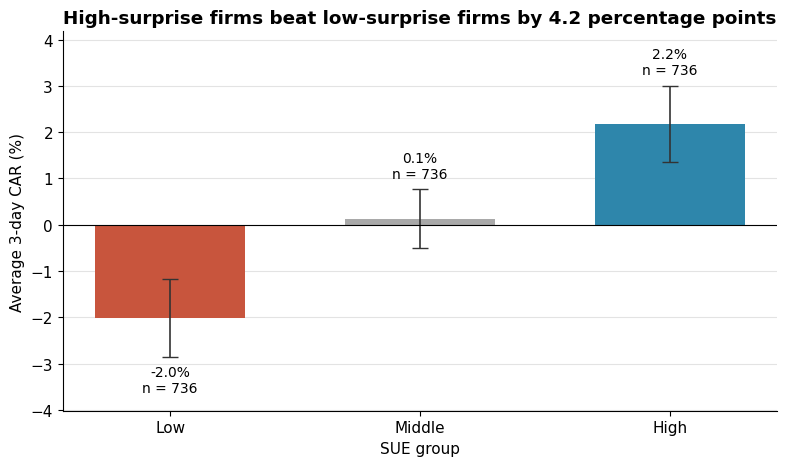

In [16]:
# ===== 2c. Figure 1, made for a client =====

plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
#sns.set_theme(style="whitegrid", font_scale=1.1, rc={"axes.grid.axis": "y"})   # 1. theme (once per notebook), horizontal lines only

COLORS = {"Low": "#C8553D", "Middle": "#A9A9A9", "High": "#2E86AB"}    # 2. colors with a meaning

mean = table["mean"] * 100
ci   = table["ci95"] * 100
spread = mean["High"] - mean["Low"]
word = "beat" if spread > 0 else "trail"
title = f"High-surprise firms {word} low-surprise firms by {abs(spread):.1f} percentage points"   # 5. the finding

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(LABELS, mean, yerr=ci, capsize=6, width=0.6,                  # 3. error bars = 95% CI
       color=[COLORS[g] for g in LABELS], error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
for i, g in enumerate(LABELS):                                        # 4. value and n on each bar
    top = mean[g] + ci[g] if mean[g] >= 0 else mean[g] - ci[g]
    ax.annotate(f"{mean[g]:.1f}%\nn = {table.loc[g, 'n']}", (i, top),
                xytext=(0, 6 if mean[g] >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if mean[g] >= 0 else "top", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)                           # 6. line at 0
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE group")
ax.set_ylabel("Average 3-day CAR (%)")
ax.margins(y=0.2)
#sns.despine(left=True)                                                # 6. no box
plt.tight_layout()
fig.savefig("figure1_groups.png", dpi=200)                            # for your slides
plt.show()

In [17]:
# ===== 3. Welch t-test: High vs Low =====
high = sample.loc[sample["group"] == "High", "CAR"]
low  = sample.loc[sample["group"] == "Low",  "CAR"]

t, p = stats.ttest_ind(high, low, equal_var=False)

gap = (high.mean() - low.mean()) * 100
print(f"High - Low = {gap:.2f} percentage points | t = {t:.2f} | p = {p:.4f}")

High - Low = 4.19 percentage points | t = 6.99 | p = 0.0000


In [18]:
# ===== 4a. Look at the extremes, then winsorize the return at 1% and 99% =====
print(sample[["SUE", "CAR"]].describe().round(3))

lo, hi = sample["CAR"].quantile([0.01, 0.99])
sample["CAR_w"] = sample["CAR"].clip(lo, hi)     # clip = pull values outside [lo, hi] to the edge
print(f"\nrows changed by winsorizing: {(sample['CAR'] != sample['CAR_w']).sum()} of {len(sample)}")

          SUE       CAR
count  2208.0  2208.000
mean      0.0     0.001
std     0.056     0.108
min    -0.717    -0.555
25%    -0.006    -0.053
50%     0.001    -0.001
75%     0.008     0.055
max     0.636     0.828

rows changed by winsorizing: 46 of 2208


In [19]:
# ===== 4b. Regression: original and winsorized =====
model   = smf.ols("CAR ~ SUE", data=sample).fit()
model_w = smf.ols("CAR_w ~ SUE", data=sample).fit()

print(model.summary())      # full results table, original
print(model_w.summary())    # full results table, winsorized

results = pd.DataFrame({
    "b (slope)":    [model.params["SUE"],  model_w.params["SUE"]],
    "p-value of b": [model.pvalues["SUE"], model_w.pvalues["SUE"]],
    "R-squared":    [model.rsquared,           model_w.rsquared],
    "n":            [int(model.nobs),          int(model_w.nobs)],
}, index=["original", "winsorized 1%/99%"]).round(4)
results

                            OLS Regression Results                            
Dep. Variable:                    CAR   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     4.939
Date:                Sun, 22 Nov 2026   Prob (F-statistic):             0.0264
Time:                        21:27:06   Log-Likelihood:                 1779.2
No. Observations:                2208   AIC:                            -3554.
Df Residuals:                    2206   BIC:                            -3543.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0010      0.002      0.420      0.6

,b (slope),p-value of b,R-squared,n
original,0.0908,0.0264,0.0022,2208
winsorized 1%/99%,0.0733,0.0542,0.0017,2208


In [20]:
sample["fyearq"] = sample["fyearq"].astype(int)           # nullable Int64 -> plain int
sample["loss"]  = (sample["epspxq"] < 0).astype(int)     # 1 = loss firm
lo, hi = sample["CAR"].quantile([0.01, 0.99])
sample["CAR_w"] = sample["CAR"].clip(lo, hi)

cl = dict(cov_type="cluster", cov_kwds={"groups": sample["gvkey"]})

m1 = smf.ols("CAR_w ~ SUE", data=sample).fit(**cl)
m2 = smf.ols("CAR_w ~ SUE + C(fyearq)", data=sample).fit(**cl)
m3 = smf.ols("CAR_w ~ SUE * loss + C(fyearq)", data=sample).fit(**cl)
from statsmodels.iolib.summary2 import summary_col

summary_col([m1, m2, m3], stars=True,
            model_names=["(1) base", "(2) yearq FE", "(3) yearq FE + loss"],
            regressor_order=["SUE", "loss", "SUE:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) base,(2) yearq FE,(3) yearq FE + loss
SUE,0.0733,0.0718,0.0892
,(0.0582),(0.0576),(0.0947)
loss,,,-0.0192***
,,,(0.0062)
SUE:loss,,,-0.0779
,,,(0.1172)
R-squared,0.0017,0.0045,0.0116
R-squared Adj.,0.0012,0.0018,0.0081
R2,0.002,0.005,0.012
n,2208,2208,2208


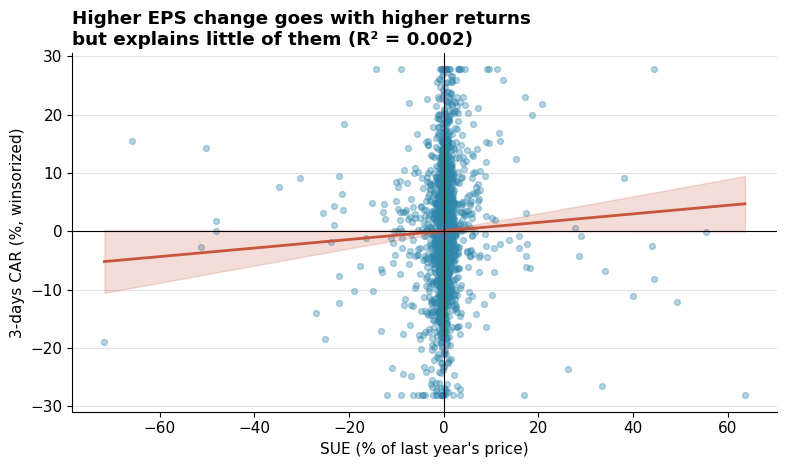

In [21]:
# ===== 4c. Figure 2: every company-year and the regression line =====
b  = model_w.params["SUE"]
r2 = model_w.rsquared
title = (f"Higher EPS change goes with {'higher' if b > 0 else 'lower'} returns\n"
         f"but explains little of them (R² = {r2:.3f})")

# the regression line and its 95% band, from the fitted model
grid = pd.DataFrame({"SUE": np.linspace(sample["SUE"].min(), sample["SUE"].max(), 100)})
pred = model_w.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(sample["SUE"] * 100, sample["CAR_w"] * 100,
           s=18, alpha=0.35, color="#2E86AB")                                   # every company-year
ax.fill_between(grid["SUE"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                color="#C8553D", alpha=0.2)                                     # 95% band
ax.plot(grid["SUE"] * 100, pred["mean"] * 100, color="#C8553D", linewidth=2)  # regression line
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of last year's price)")
ax.set_ylabel("3-days CAR (%, winsorized)")
ax.spines[["top", "right"]].set_visible(False)                                  # no box
plt.tight_layout()
fig.savefig("figure2_regression.png", dpi=200)
plt.show()

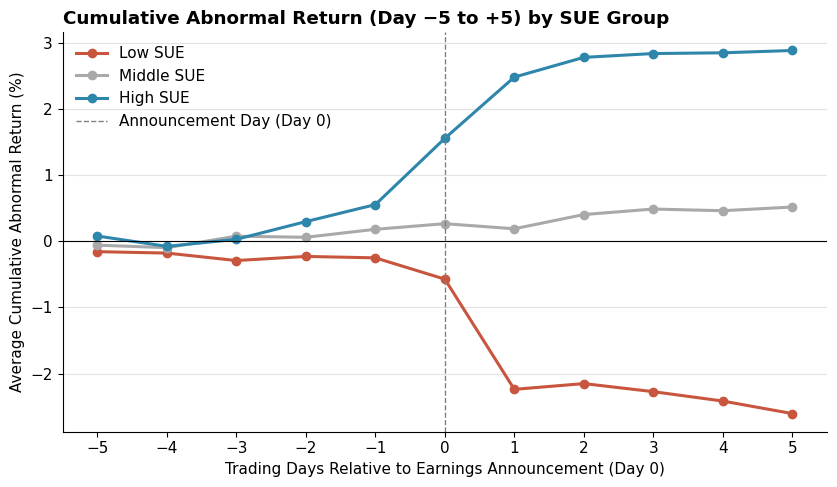

In [22]:
# ===== Event-time CAR from day -5 to day +5 by SUE group =====
days = list(range(-5, 6))

# Use CRSP DSI dates as the common market trading calendar
'''market_calendar = pd.DatetimeIndex(
    pd.to_datetime(market_daily["date"]).dt.normalize().unique()
).sort_values()'''

market_calendar = (
    market_daily["date"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

market_dates = market_calendar.to_numpy(dtype="datetime64[ns]")
# Index each stock's abnormal returns by date
daily_by_permno = {
    int(p): (
        g.assign(date=pd.to_datetime(g["date"]).dt.normalize())
         .drop_duplicates(subset="date")
         .set_index("date")
         .sort_index()
    )
    for p, g in daily.groupby("permno")
}

car_paths = []

for _, event in sample.iterrows():
    g = daily_by_permno.get(int(event["permno"]))

    if g is None or g.empty:
        continue

    # Day 0 = first CRSP market trading date on or after RDQ
    rdq = pd.Timestamp(event["rdq"]).normalize()
    pos0 = market_calendar.searchsorted(rdq, side="left")

    # Require a complete [-5, +5] market trading-day window
    if pos0 < 5 or pos0 + 5 >= len(market_calendar):
        continue

    window_dates = market_calendar[pos0 - 5 : pos0 + 6]

    # Align the stock's abnormal returns to the market calendar
    w = g.reindex(window_dates)
    ars = w["AR"].to_numpy(dtype=float)

    # Skip events with any missing abnormal return
    if not np.isfinite(ars).all():
        continue

    # Cumulative abnormal return from day -5 through each day
    cum_ar = np.cumsum(ars)

    row = {
        "event_id": event["event_id"],
        "group": event["group"]
    }

    for d, val in zip(days, cum_ar):
        row[d] = val

    car_paths.append(row)

# Calculate average CAR path by SUE group
paths_df = pd.DataFrame(car_paths)

if paths_df.empty:
    raise ValueError("No events have a complete [-5, +5] trading-day window.")

mean_paths = paths_df.groupby("group", observed=True)[days].mean() * 100

# ===== Plot the CAR lines =====
fig, ax = plt.subplots(figsize=(8.5, 5))

for grp in LABELS:
    if grp in mean_paths.index:
        ax.plot(
            days,
            mean_paths.loc[grp],
            marker="o",
            linewidth=2.2,
            label=f"{grp} SUE",
            color=COLORS[grp]
        )

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(
    0, color="gray", linestyle="--", linewidth=1,
    label="Announcement Day (Day 0)"
)

ax.set_title(
    "Cumulative Abnormal Return (Day −5 to +5) by SUE Group",
    loc="left",
    fontweight="bold"
)
ax.set_xlabel("Trading Days Relative to Earnings Announcement (Day 0)")
ax.set_ylabel("Average Cumulative Abnormal Return (%)")
ax.set_xticks(days)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig("figure3_car_event_window.png", dpi=200)
plt.show()